<div align="center">

<h1> <b> MAGNETOMETRÍA DE TORQUE EN UNA CAJA CON ANISOTROPÍA UNIAXIAL </b> </h1>

</div>

<br>

<hr size=10 noshade color="green">
<p>
<p><img alt="UdeA logo" height="180px" src="https://upload.wikimedia.org/wikipedia/commons/archive/f/fb/20161010213812%21Escudo-UdeA.svg" align="left" hspace="100px" vspace="4px"></p>

<div align="right">       

<h3><i> <b>Cristian Camilo Vergara Restrepo</b> <br>
Universidad de Antioquia <br>
Instituto de Física  <br>
</i></h3>
</div>


---

## 1. Objetivo y contexto

En la magnetometría de torque se aplica un campo magnético intenso con una orientación variable respecto de una muestra y se mide el torque que el campo ejerce sobre ella. La dependencia angular del torque revela la anisotropía magnética del material. Este notebook simula ese experimento con Ubermag y el paquete `mag2exp` (Beg et al., 2022; Holt et al., 2025): se relaja una caja con anisotropía uniaxial, se rota un campo de 3 T en un plano que contiene al eje fácil y se calcula el torque en cada ángulo. El ejemplo parte del cuaderno *Torque magnetometry* de la documentación de Ubermag (Ubermag developers, s. f.). Las operaciones de cálculo de las celdas de código son las del ejemplo; las celdas llevan comentarios y la figura del barrido cambia de estilo (líneas de $\pm K$ discontinuas y ejes rotulados en español).

El desarrollo sigue este orden: fundamentos del torque y del modelo de macroespín, definición y relajación del sistema, cálculo del torque, barrido angular, análisis del resultado y comparación con MuMax3.

## 2. Fundamentos físicos

### 2.1 Torque sobre una muestra magnética

Un momento magnético $\mathbf m$ en un campo de inducción $\mathbf B$ experimenta el torque $\boldsymbol\tau=\mathbf m\times\mathbf B$ (Jackson, 1999; Dunsmore et al., 2022; Blundell, 2001). En términos del campo aplicado, $\mathbf B=\mu_0\mathbf H_\mathrm{app}$, y con $\mathbf m=\int_V\mathbf M\,dV$ el torque total sobre la muestra es

$$\boldsymbol\Gamma=\mu_0\int_V\mathbf M\times\mathbf H_\mathrm{app}\,dV=\mu_0V\,\langle\mathbf M\rangle\times\mathbf H_\mathrm{app}.$$

La función `mag2exp.magnetometry.torque` devuelve este torque normalizado por el volumen (Holt et al., 2025, ec. 4):

$$\boldsymbol\tau=\frac{\boldsymbol\Gamma}{V}=\mu_0\langle\mathbf M\rangle\times\mathbf H_\mathrm{app},$$

con unidades de N m$^{-2}$, equivalentes a J m$^{-3}$. Por eso se puede comparar directamente con la constante de anisotropía $K$, también en J m$^{-3}$, como hace la gráfica final con las líneas rojas en $\pm K$.

### 2.2 Energía del sistema

El sistema incluye intercambio, anisotropía uniaxial, Zeeman y el campo desmagnetizante $\mathbf H_d$ producido por la propia magnetización (Brown, 1963; Aharoni, 2000):

$$E=\int_V\Big[A|\nabla\mathbf m|^2+K\,|\mathbf m\times\mathbf u|^2-\mu_0M_s\,\mathbf m\cdot\mathbf H_\mathrm{app}-\tfrac12\mu_0M_s\,\mathbf m\cdot\mathbf H_d\Big]dV .$$

En el equilibrio $\mathbf m\times\mathbf H_\mathrm{eff}=\mathbf 0$. El torque que el campo ejerce sobre la magnetización se transmite a la red a través de la anisotropía cristalina y de la forma de la muestra, de modo que el torque medido equivale al torque con signo contrario de los campos internos. El intercambio no contribuye a la suma sobre toda la muestra, porque es un acoplamiento interno.

### 2.3 Límite de macroespín

Si la magnetización es uniforme y se ignora la desmagnetización, la densidad de energía depende solo del ángulo $\theta$ de $\mathbf m$ con el eje $z$ y del ángulo $\varphi$ del campo (Stoner & Wohlfarth, 1948):

$$e(\theta)=K\sin^2\theta-\mu_0M_sH\cos(\theta-\varphi).$$

Con $\mathbf H=H(0,\sin\varphi,\cos\varphi)$ y $\mathbf m=(0,\sin\theta,\cos\theta)$, el producto $\mathbf m\times\mathbf H$ solo tiene componente $x$: $\tau_x=\mu_0M_sH\sin(\theta-\varphi)$. La condición de equilibrio $\partial e/\partial\theta=0$ da $K\sin2\theta+\mu_0M_sH\sin(\theta-\varphi)=0$, y por tanto

$$\tau_x=-K\sin2\theta .$$

A campo muy alto, $\theta\to\varphi$ y $\tau_x\to-K\sin2\varphi$: una sinusoide de periodo $\pi$ y amplitud $K$. A campo finito la magnetización se atrasa respecto del campo, la curva se deforma ("cizalla") y el máximo de $|\tau_x|$ se desplaza. El campo de anisotropía $H_K=2K/(\mu_0M_s)$ fija la escala: para $H>H_K$ la magnetización sigue al campo sin saltos irreversibles a ningún ángulo, y la curva de torque es univaluada.

### 2.4 Efecto de la forma

La caja no es una esfera, y su campo desmagnetizante añade una anisotropía de forma que se suma a la cristalina y reduce la anisotropía efectiva cuando el eje fácil es la dirección corta de la caja. Para una magnetización no uniforme no existe una expresión cerrada (con magnetización uniforme sí, véase la sección 8.3), y por eso se simula. Holt et al. (2025) atribuyen a la desmagnetización las desviaciones de la sinusoide ideal que se observan incluso a 3 T.

## 3. Geometría, material y estado inicial

La región es una caja de $300\times300\times100$ nm$^3$ con celdas de 5 nm ($60\times60\times20$ celdas). Los parámetros son $M_s=9.65\times10^{5}$ A/m, $A=8.78\times10^{-13}$ J/m, $K=1.18\times10^{6}$ J/m$^3$ con $\mathbf u=\hat z$, y el campo rotatorio tiene módulo $H=2.38\times10^{6}$ A/m, es decir, $\mu_0H\approx2.99$ T. El término Zeeman arranca en cero y `mm.Demag()` activa el campo desmagnetizante completo.

Algunas escalas ayudan a interpretar el problema:

| Magnitud | Expresión | Valor |
|---|---|---|
| Campo de anisotropía | $H_K=2K/(\mu_0M_s)$ | $1.95\times10^{6}$ A/m |
| Cociente $H/H_K$ | | 1.22 |
| Densidad de energía magnetostática | $K_d=\mu_0M_s^2/2$ | $5.85\times10^{5}$ J/m$^3$ |
| Cociente $K/K_d$ | | 2.0 |
| Longitud de intercambio | $\ell_\mathrm{ex}=\sqrt{2A/(\mu_0M_s^2)}$ | 1.2 nm |
| Ancho de pared | $\pi\sqrt{A/K}$ | 2.7 nm |

El campo aplicado supera a $H_K$, así que no se esperan saltos de magnetización. Como $K/K_d>1$, la anisotropía cristalina domina sobre la de forma, aunque esta última no es despreciable. El tamaño de celda es mayor que $\ell_\mathrm{ex}$ y que el ancho de pared, lo cual es aceptable aquí porque el estado es casi uniforme y no se forman paredes de dominio. El mismo tamaño de celda no sería suficiente para estudiar texturas con paredes.

El código fija la semilla de `numpy` por reproducibilidad, aunque el flujo no genera números aleatorios y el resultado no depende de ella. El estado inicial es uniforme a lo largo de $+z$ con módulo $M_s$, y la última línea de la celda grafica $M_z$ en el plano central.

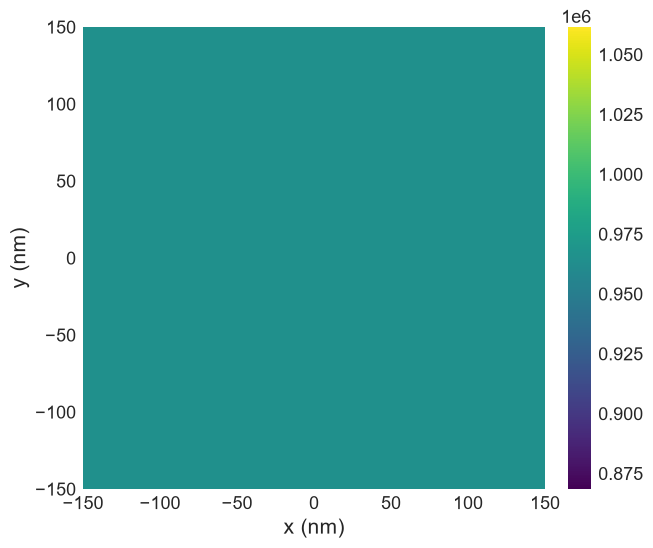

In [1]:
import discretisedfield as df
import matplotlib.pyplot as plt
import micromagneticmodel as mm
import numpy as np
import oommfc as oc

# Fijamos la semilla de números aleatorios para garantizar que cualquier proceso
# que involucre azar se comporte siempre igual si volvemos a correr el código.
np.random.seed(1)

# Definimos las dimensiones de la muestra magnética (una caja de 300 x 300 x 100 nanómetros).
# En micromagnetismo trabajamos en escala nanométrica porque a esa escala la magnetización se describe como un campo continuo.
region = df.Region(p1=(-150e-9, -150e-9, 0), p2=(150e-9, 150e-9, 100e-9))

# Dividimos la caja continua en pequeños cubos de simulación (celdas de 5 nanómetros).
# Esta malla es necesaria para que el ordenador pueda resolver las ecuaciones numéricamente.
# El tamaño de celda debe ser muy pequeño para capturar bien cómo rotan los espines internamente.
mesh = df.Mesh(region=region, cell=(5e-9, 5e-9, 5e-9))

# Definimos la magnetización de saturación (Ms), que es el límite de orden magnético del material,
# y la intensidad del campo magnético externo (H_mag) que usaremos para forzar el giro de los espines.
Ms = 9.65e5
H_mag = 2.38e6

# Creamos el sistema físico definiendo sus interacciones energéticas:
# 1. Exchange: Fuerza cuántica que busca mantener los espines paralelos entre vecinos.
# 2. UniaxialAnisotropy: Propiedad del cristal que hace que los espines prefieran alinearse en el eje z.
# 3. Demag: Campo interno creado por el propio imán que tiende a desmagnetizarlo debido a su forma.
# 4. Zeeman: Energía de interacción con el campo externo aplicado (que inicia en cero).
system = mm.System(name="Box2")
system.energy = (
    mm.Exchange(A=8.78e-13)
    + mm.UniaxialAnisotropy(K=1.18e6, u=(0, 0, 1))
    + mm.Demag()
    + mm.Zeeman(H=(0, 0, 0))
)

# Inicializamos todos los espines del material apuntando uniformemente hacia arriba (eje z).
system.m = df.Field(mesh, nvdim=3, value=(0, 0, 1), norm=Ms)

# Extraemos la componente z de la magnetización en el plano medio y la graficamos para verificar
# que el estado inicial del material sea uniforme.
system.m.z.sel("z").mpl.scalar()

## 4. Relajación a campo cero

`MinDriver` minimiza la energía a partir de la configuración uniforme. La gráfica muestra la componente $z$ y la proyección en el plano $xy$. A campo cero, el único efecto que aparece es el de los bordes: la desmagnetización inclina ligeramente la magnetización cerca de las caras laterales para reducir las cargas magnéticas superficiales. Según la barra de color, $M_z$ varía solo entre unos $9.6498\times10^{5}$ y $9.6500\times10^{5}$ A/m (es decir, menos de $3\times10^{-5}M_s$ de variación y una inclinación menor que $0.5^{\circ}$), de modo que el estado es prácticamente uniforme a lo largo del eje fácil.

Running OOMMF (ExeOOMMFRunner)[2026-10-29T14:54:22]... (6.5 s)


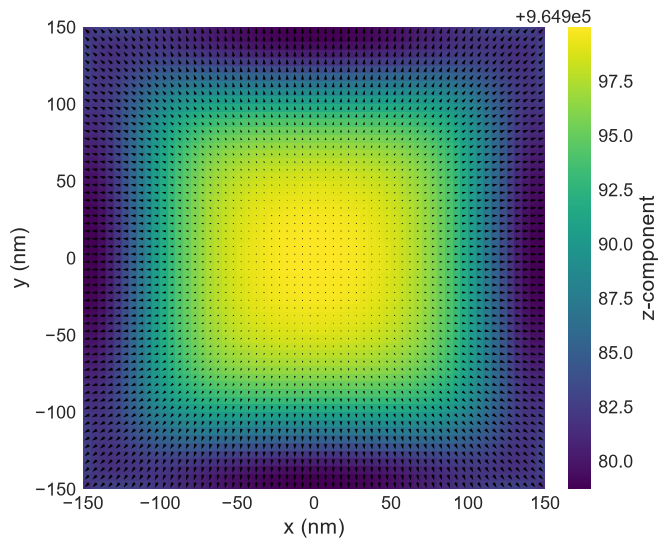

In [2]:
# Usamos el motor de simulación para buscar el estado donde el material sea más estable (mínima energía).
# El software rota los espines paso a paso hasta que las fuerzas magnéticas se equilibran a campo cero.
md = oc.MinDriver()
md.drive(system)

# Graficamos el estado relajado del material. Aquí se puede observar cómo el borde de la caja
# distorsiona levemente la dirección de los espines para reducir la energía del campo desmagnetizante,
# mientras que el centro permanece fiel al eje de anisotropía vertical.
system.m.sel("z").mpl()

## 5. Cálculo del torque

`mag2exp.magnetometry.torque(system.m, system.energy.zeeman.H)` evalúa $\boldsymbol\tau=\mu_0\langle\mathbf M\rangle\times\mathbf H_\mathrm{app}$ (sección 2.1) con el campo de magnetización relajado y el campo Zeeman actual, que aquí es nulo. El resultado es el vector nulo, como debe ser sin campo aplicado.

In [3]:
import mag2exp

# El torque es la fuerza de giro que siente la magnetización debido a la presencia de un campo externo.
# Matemáticamente, es el producto cruz entre ambos vectores. Calculamos este valor para nuestro estado actual.
# Como el campo magnético aplicado en este momento es cero, el torque resultante debe ser nulo.
mag2exp.magnetometry.torque(system.m, system.energy.zeeman.H)

array([0., 0., 0.])

## 6. Barrido angular del campo

Se rota el campo en el plano $yz$ con $\mathbf H=H_\mathrm{mag}(0,\sin\varphi,\cos\varphi)$, donde $\varphi$ se mide desde $+z$ hacia $+y$, a lo largo de 71 ángulos entre $0$ y $2\pi$ (paso $2\pi/70$). En cada ángulo se actualiza el campo Zeeman, se vuelve a minimizar la energía y se calcula el torque. El estado de equilibrio de un ángulo es el punto de partida del siguiente, de modo que el barrido sigue la rama continua de equilibrios, como en un experimento real con rotación lenta. Esto es válido porque $H>H_K$ y no hay saltos.

Como $\mathbf M$ y $\mathbf H$ permanecen en el plano $yz$, solo $\tau_x$ es distinto de cero, y por eso se grafica esa componente. Las líneas rojas en $\pm K$ marcan la amplitud del límite de macroespín a campo infinito. El eje vertical lleva las unidades N m$^{-2}$ de la sección 2.1. El barrido es secuencial porque cada minimización parte del estado anterior.

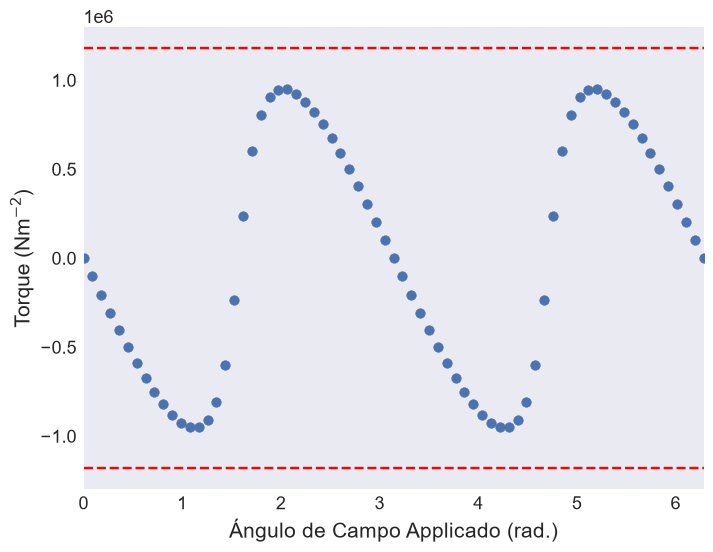

In [4]:
# Preparamos una lista de 71 ángulos para simular una rotación completa (de 0 a 360 grados en radianes).
# Creamos contenedores vacíos para guardar el torque calculado en cada una de las direcciones de giro.
angles = np.linspace(0, 2 * np.pi, 71)
torque_val_x = np.full_like(angles, np.nan)
torque_val_y = np.full_like(angles, np.nan)
torque_val_z = np.full_like(angles, np.nan)

# Iniciamos el experimento rotando el campo magnético en el plano vertical (YZ).
for i, angle in enumerate(angles):
    # Aplicamos el campo externo con la inclinación del ángulo actual de la rotación.
    system.energy.zeeman.H = (0, H_mag * np.sin(angle), H_mag * np.cos(angle))

    # Dejamos que los espines de la muestra se reorienten y busquen su nuevo equilibrio bajo este campo.
    # El estado final obtenido sirve como punto de partida para el siguiente ángulo, emulando un giro continuo.
    md.drive(system, verbose=0)

    # Calculamos el torque que experimenta el material en este equilibrio y guardamos sus componentes.
    torque_val_x[i], torque_val_y[i], torque_val_z[i] = mag2exp.magnetometry.torque(
        system.m, system.energy.zeeman.H
    )

# Graficamos el torque medido a lo largo de todo el barrido angular.
fig, ax = plt.subplots(dpi=100)

# Dibujamos líneas de referencia rojas en los valores límite de la constante de anisotropía.
# Si la muestra fuera un único espín perfecto sin efectos de borde, la curva tocaría exactamente este tope.
# Las desviaciones que observamos nos permiten entender la influencia de la geometría y la forma de la muestra.
ax.hlines(system.energy.uniaxialanisotropy.K, xmin=np.min(angles), xmax=np.max(angles), color="r", linestyle="--")
ax.hlines(-system.energy.uniaxialanisotropy.K, xmin=np.min(angles), xmax=np.max(angles), color="r", linestyle="--")

# Representamos los puntos calculados en la simulación para visualizar la curva de torque característica.
ax.scatter(angles, torque_val_x, label="Torque simulado (x)")
ax.set_xlabel("Ángulo de Campo Aplicado (rad.)")
ax.set_ylabel(r"Torque (Nm$^{-2}$)")
ax.set_xlim([0, 2 * np.pi])
plt.show()

## 7. Análisis del resultado

La curva obtenida es periódica con periodo $\pi$, como corresponde a una anisotropía uniaxial, y tiene la forma sinusoidal cizallada esperada: cruza cero en $\varphi=0$, $\pi/2$ y $\pi$, y su pendiente es más empinada cerca de $\pi/2$ (campo a lo largo del eje difícil) que cerca de $0$. El signo negativo para ángulos pequeños es el de $\tau_x=-K\sin2\theta$. La amplitud simulada es de aproximadamente $0.95\times10^{6}$ N m$^{-2}$, por debajo de $K=1.18\times10^{6}$ J m$^{-3}$.

Un cálculo de macroespín con los mismos valores de $K$, $M_s$ y $H$ (sin desmagnetización) da una curva con la misma simetría, con extremos en $\varphi\approx1.21$ y $1.94$ rad (los puntos más cercanos de la malla de 71 ángulos son 1.17 y 1.97 rad) y amplitud igual a $K$; la cizalla es, por tanto, un efecto del campo finito ($H/H_K=1.22$). La amplitud menor de la simulación se debe a la anisotropía de forma de la caja, que reduce la anisotropía efectiva (sección 2.4); la sección 8.3 lo comprueba de forma cuantitativa con los factores desmagnetizantes de la caja.

Una consecuencia experimental es que, con un campo de solo $1.2H_K$, ajustar $\tau=-K\sin2\varphi$ a los datos subestimaría la anisotropía efectiva: la forma de la curva exige el modelo completo.

## 8. Comparación con el enfoque de MuMax3

El script `mumax3/torque_magnetometry_mumax3.mx3` repite este experimento en MuMax3 con la misma malla, los mismos parámetros y el mismo barrido (71 ángulos entre $0$ y $2\pi$, cada minimización parte del estado anterior). Se ejecutó con `mumax3 -f`. Las secciones 8.1 a 8.5 resumen lo que devolvió; los cálculos de macroespín y la comparación con los datos numéricos de Ubermag de las secciones 8.1 y 8.3 están en `scripts/validate_torque_macrospin.py`.

| Elemento | Ubermag con OOMMF | MuMax3 |
|---|---|---|
| Material | $M_s=9.65\times10^{5}$ A/m, $A=8.78\times10^{-13}$ J/m | `Msat`, `Aex` con los mismos valores |
| Anisotropía | $K=1.18\times10^{6}$ J/m$^3$, $\mathbf u=\hat z$ | `Ku1`, `anisU` con los mismos valores |
| Campo aplicado | $\mathbf H$ en A/m, $H=2.38\times10^{6}$ A/m | $\mathbf B=\mu_0\mathbf H$ en T, $\mu_0H\approx2.99$ T |
| Malla | $60\times60\times20$ celdas de 5 nm | `SetGridSize(60, 60, 20)`, `SetCellSize(5e-9, 5e-9, 5e-9)` |
| Minimización | `MinDriver` (evolver de gradiente conjugado, `CGEvolver`) | `Minimize()`: descenso de gradiente tipo LaBonte (Exl et al., 2014) |
| Criterio de parada | `stopping_mxHxm` (par residual máximo $\lvert\mathbf m\times\mathbf H\rvert$, en A/m); 0.1 A/m por defecto en `oommfc` 0.66.0 | `MinimizerStop` $=10^{-6}$ (cambio máximo de $\mathbf m$ entre iteraciones), el valor por defecto de `Minimize()` |
| Torque por unidad de volumen | `mag2exp.magnetometry.torque` $=\mu_0\langle\mathbf M\rangle\times\mathbf H$ | $M_s\langle\mathbf m\rangle\times\mathbf B_\mathrm{ext}$, calculado en el script |
| Hardware y precisión | OOMMF en CPU | GPU NVIDIA, precisión simple |
| Ejecución | Una llamada a OOMMF por cada `md.drive` | Todo el barrido en un único proceso |

En `oommfc` 0.66.0, un `MinDriver` creado sin argumentos usa el evolver `CGEvolver` y `stopping_mxHxm` $=0.1$ A/m: la función que escribe el archivo de entrada de OOMMF les asigna esos valores si no se dan (`oommfc/scripts/driver.py`), y quedan escritos en el archivo `.mif` de la carpeta de trabajo (`Box2/`).

Las dos definiciones del torque son equivalentes porque `m.Average()` es la media de $\mathbf m$ sobre la geometría (Vansteenkiste et al., 2014; Holt et al., 2025).

### 8.1 Resultado del barrido

| Magnitud | MuMax3 |
|---|---:|
| Máximo de $\tau_x$ | $+9.4873\times10^{5}$ N m$^{-2}$ (en $\varphi=5.206$ rad) |
| Mínimo de $\tau_x$ | $-9.4873\times10^{5}$ N m$^{-2}$ (en $\varphi=1.077$ rad) |
| $\max\lvert\tau_x(\varphi)-\tau_x(\varphi+\pi)\rvert$ | $0.26$ N m$^{-2}$ ($2.8\times10^{-7}$ de la amplitud) |
| $\max\lvert\tau_x(\varphi)+\tau_x(2\pi-\varphi)\rvert$ | $0.34$ N m$^{-2}$ |
| $\max\lvert\tau_y\rvert$, $\max\lvert\tau_z\rvert$ | $2.0\times10^{-3}$ y $5.5\times10^{-3}$ N m$^{-2}$ |

Por el periodo $\pi$, el máximo y el mínimo se repiten en $\varphi=2.064$ y $4.219$ rad. Los cuatro valores coinciden hasta $0.2$ N m$^{-2}$, de modo que cuál de ellos resulta el extremo depende del ruido de la precisión simple.

La curva de MuMax3 tiene las propiedades que se esperan y que se discuten en la sección 7: periodo $\pi$, simetría impar respecto de $\varphi=0$ y amplitud menor que $K$. Las componentes $\tau_y$ y $\tau_z$ son nulas hasta la precisión simple de la GPU, lo que confirma que $\mathbf M$ y $\mathbf H$ permanecen en el plano $yz$.

Para compararla con Ubermag se usan sus datos numéricos, guardados aparte (`results/ubermag_arrays_torque_magnetometry_uniaxial_box.npz`) con una pasada del benchmark que añade una celda al final de una copia del notebook. La figura superpone las dos curvas al modelo de macroespín de la sección 8.3. La diferencia máxima entre Ubermag y MuMax3 en los 71 ángulos es de $37$ N m$^{-2}$, $3.9\times10^{-5}$ de la amplitud, con un valor eficaz de $23$ N m$^{-2}$; las amplitudes son $9.4870\times10^{5}$ y $9.4873\times10^{5}$ N m$^{-2}$. En Ubermag, las simetrías de la curva se cumplen a $2\times10^{-11}$ de la amplitud, el nivel de la doble precisión, frente a $2.8\times10^{-7}$ en MuMax3, y los dos se apartan del macroespín con anisotropía de forma en un máximo de 1.2 %.

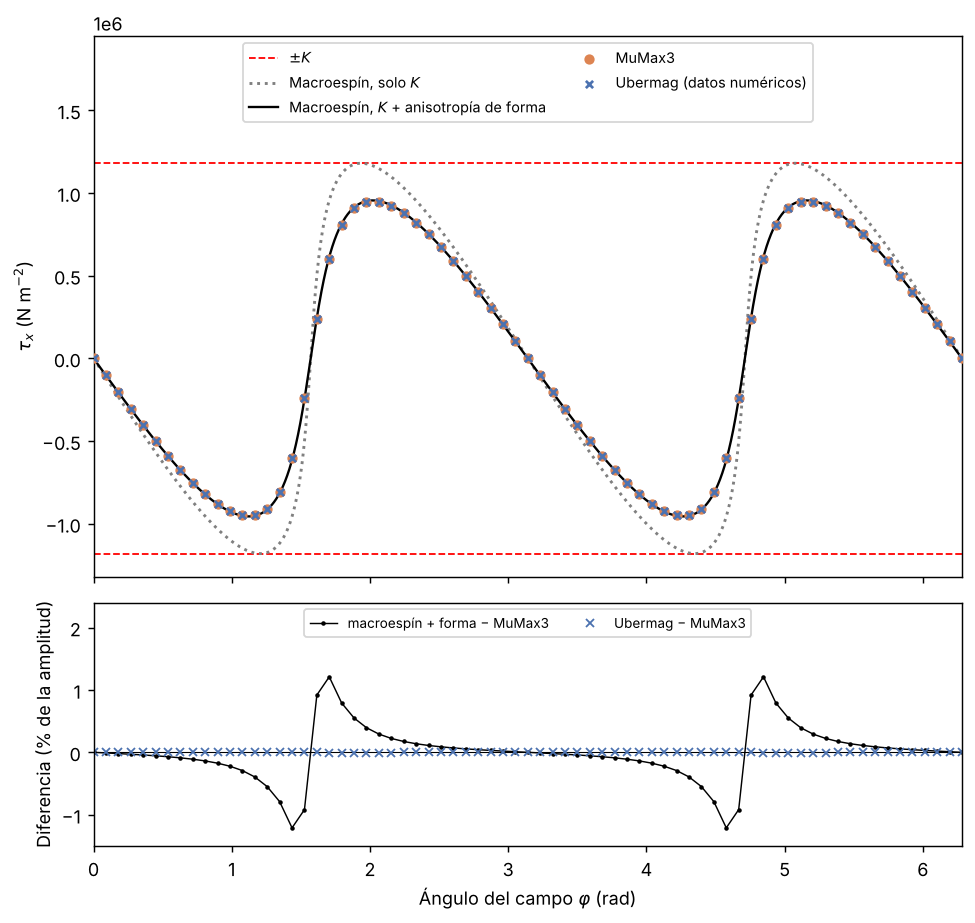

### 8.2 Estado a campo cero

A campo cero, MuMax3 devuelve $\langle\mathbf m\rangle=(1.0\times10^{-10},\,-4.2\times10^{-10},\,0.9978)$. Ese promedio sobre todo el volumen no se debe comparar con el corte del plano central de la sección 4. Al separar el campo guardado por capas:

| Región | Intervalo de $m_z$ | Inclinación máxima |
|---|---|---:|
| Dos capas centrales | $0.99998$ a $1$ | $0.38^{\circ}$ |
| Toda la caja | hasta $0.967$ | $14.8^{\circ}$ |

El rango del plano central ($M_z$ entre $9.6498\times10^{5}$ y $9.6500\times10^{5}$ A/m) coincide con el que se leyó en la barra de color de Ubermag en la sección 4, y la inclinación es menor que $0.5^{\circ}$ en ambos. El valor medio de $0.9978$ lo fija la inclinación cerca de las caras y las esquinas de la caja, donde la desmagnetización inclina la magnetización más que en el centro.

### 8.3 La anisotropía de forma, cuantificada

En la sección 7 se atribuyó la amplitud de $0.95\times10^{6}$ N m$^{-2}$ (menor que $K$) a la anisotropía de forma. Con los datos de MuMax3 se puede comprobar. Para una magnetización uniforme, los factores desmagnetizantes (magnetométricos) de un prisma de $300\times300\times100$ nm$^3$ se calculan con la fórmula analítica de Aharoni (1998). Se comprobó que la fórmula da $1/3$ para el cubo y que $N_x+N_y+N_z=1$:

| Magnitud | Valor |
|---|---:|
| $N_z$ (dirección corta, el eje fácil) | $0.589$ |
| $N_x=N_y$ | $0.205$ |
| $K_d=\tfrac12\mu_0M_s^2$ | $5.85\times10^{5}$ J/m$^3$ |
| Anisotropía de forma, $K_d\,(N_z-N_y)$ | $2.25\times10^{5}$ J/m$^3$ |
| Anisotropía efectiva, $K_\mathrm{eff}=K-K_d\,(N_z-N_y)$ | $9.55\times10^{5}$ J/m$^3$ |
| $H/H_{K,\mathrm{eff}}$, con $H_{K,\mathrm{eff}}=2K_\mathrm{eff}/(\mu_0M_s)$ | $1.51$ |

Con la energía de macroespín $e(\theta)=K\sin^2\theta+\tfrac12\mu_0M_s^2\,(N_z\cos^2\theta+N_y\sin^2\theta)-\mu_0M_sH\cos(\theta-\varphi)$ y $\tau_x=\mu_0M_sH\sin(\theta-\varphi)$, se obtiene:

| Modelo | Amplitud de $\tau_x$ (N m$^{-2}$) | Máxima diferencia con MuMax3 |
|---|---:|---:|
| Macroespín, solo $K$ | $1.1800\times10^{6}$ | 37 % de la amplitud |
| Macroespín, $K$ + forma | $9.553\times10^{5}$ | 1.2 % de la amplitud |
| MuMax3 (simulación) | $9.487\times10^{5}$ | |

El modelo con anisotropía de forma reproduce la curva completa de la simulación (curva negra en la figura de la sección 8.1): la amplitud es $K_\mathrm{eff}$ y no $K$, y los extremos se desplazan a $\varphi\approx1.12$ y $2.02$ rad, entre los puntos de la malla donde MuMax3 tiene sus valores más grandes. Por tanto, las líneas rojas en $\pm K$ de la gráfica del notebook marcan la amplitud de una muestra sin forma, y para esta caja la referencia adecuada es $\pm K_\mathrm{eff}\approx\pm9.55\times10^{5}$ N m$^{-2}$. La diferencia restante, de hasta 1.2 %, es compatible con que la magnetización no es exactamente uniforme (se inclina cerca de las caras, sección 8.2) y con la discretización en celdas de 5 nm, pero no se separó cada contribución.

### 8.4 Tiempos de ejecución

| Componente | Versión o modelo |
|---|---|
| Sistema | Windows 11 (10.0.26300), Python 3.12.14 |
| CPU | Intel Core i7-14650HX |
| GPU | NVIDIA GeForce RTX 5060 Laptop GPU (8 GB), controlador 621.01 |
| Ubermag | `discretisedfield` 0.92.0, `micromagneticmodel` 0.65.0, `oommfc` 0.66.0, `mag2exp` 0.64.0 |
| MuMax3 | 3.12 (`windows_amd64`, Go 1.26.0, CUDA 12.9) |

Protocolo: el notebook completo se ejecutó con `nbclient` sobre una copia en un directorio temporal (3 repeticiones, 31 de octubre de 2026). El script `.mx3` se ejecutó con `mumax3 -f` tras una ejecución de calentamiento que no se cuenta, para que los kernels de CUDA ya estén en caché (3 repeticiones). En ambos casos se mide el tiempo de pared del proceso completo: en Ubermag incluye el arranque del kernel de Jupyter, las importaciones y las gráficas, y en MuMax3 el arranque de CUDA y la escritura de archivos.

| Enfoque | Mediana (s) | Mín. (s) | Máx. (s) |
|---|---:|---:|---:|
| Ubermag + OOMMF (notebook completo) | 470.40 | 470.03 | 471.19 |
| MuMax3 (script completo) | 1.49 | 1.48 | 1.57 |

El cociente de medianas es 316.0. En Ubermag, el tiempo por parte del notebook fue:

| Parte del notebook | Tiempo (s) |
|---|---:|
| Importaciones y definición del sistema (sección 3) | 2.7 |
| Relajación a campo cero (sección 4; una llamada a OOMMF) | 6.8 |
| Torque a campo cero con `mag2exp` (sección 5) | 0.03 |
| Barrido angular, 71 llamadas a `md.drive` (sección 6) | 459.6 |
| Arranque del kernel y cierre (no atribuible a una celda) | 1.3 |

El barrido cuesta $459.6/71\approx6.47$ s por llamada y es el 98 % del notebook; las 72 llamadas a OOMMF ocupan el 99 %. MuMax3 hizo las 72 minimizaciones de la malla de 72 000 celdas, incluido el arranque de CUDA, en un solo proceso en 1.5 s, menos de lo que tarda una sola llamada a OOMMF.

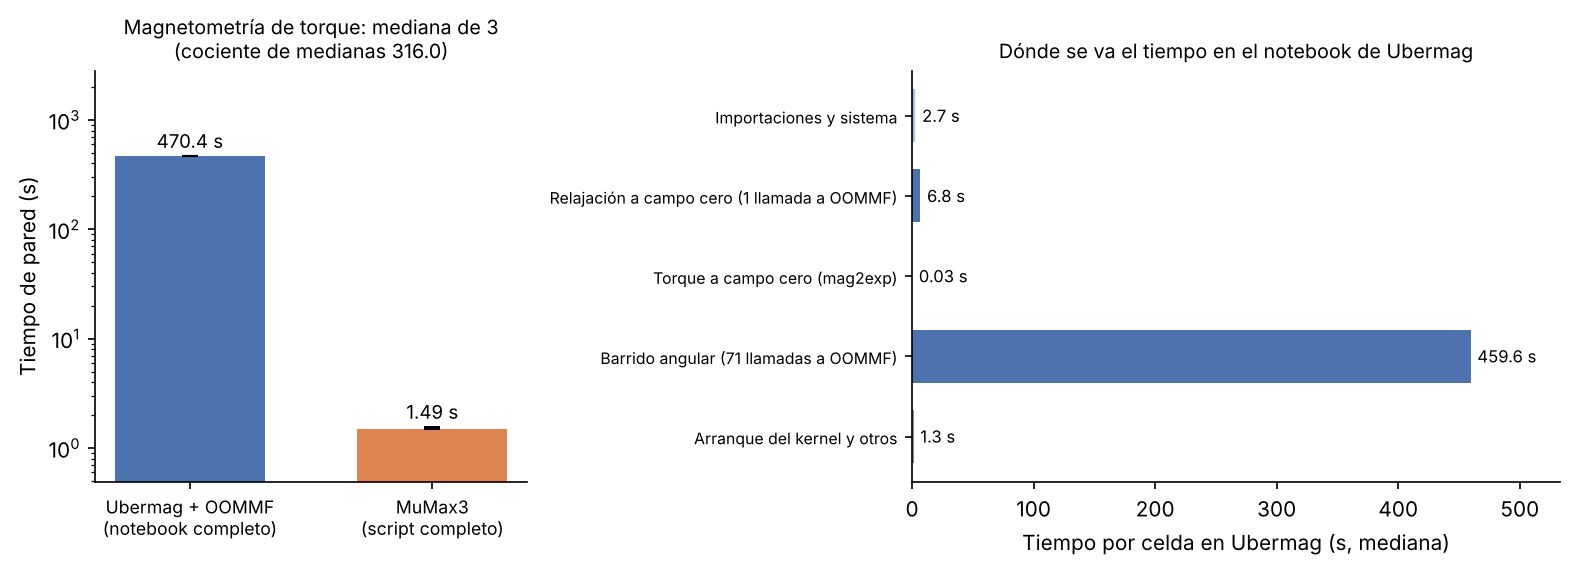

**Costo fijo y costo por celda.** Para separar el arranque de cada llamada del cálculo, `scripts/benchmark_scaling.py` mide una sola minimización de este sistema, desde $\mathbf m=\hat z$ con el campo de $2.38\times10^{6}$ A/m a 45° en el plano $yz$, en cajas de $n\times n\times n/3$ celdas de 5 nm, con $N$ entre 72 y 72 000 (la malla del notebook), 3 repeticiones y en la misma sesión. En Ubermag se mide cada llamada a `md.drive`; en MuMax3, un proceso completo con `Minimize()` y otro que solo prepara el sistema y evalúa la energía. Los dos códigos llegan al mismo estado ($\langle m_z\rangle=0.87586$ con 72 000 celdas). El ajuste $t=t_0+cN$ sobre las medianas da:

| Medición | $t_0$ (s) | $c$ (µs por celda) | $t$ con 72 000 celdas (s) |
|---|---:|---:|---:|
| Ubermag + OOMMF, una llamada a `md.drive` | $6.15\pm0.02$ | $4.6\pm0.4$ | 6.48 |
| MuMax3, un proceso con `Minimize()` | $0.126\pm0.001$ | $1.02\pm0.02$ | 0.20 |

En OOMMF, el cálculo con 72 000 celdas añade unos 0.33 s a un costo fijo de 6.15 s, que es el 95 % de cada llamada. En `oommfc` 0.66.0, cada `md.drive` escribe el archivo `.mif` y la magnetización inicial, ejecuta `boxsi +fg <archivo>.mif -exitondone 1` en un proceso nuevo de OOMMF, lee del disco el estado y la tabla de resultados y, en Windows, ejecuta además `killoommf all`, otro proceso de OOMMF (`oommfc/oommf/oommf.py`). En MuMax3, la diferencia entre el proceso con `Minimize()` y el que solo prepara el sistema queda por debajo de la dispersión entre procesos (unos 0.02 s), de modo que una minimización no se puede aislar así. Del barrido completo se estima en $(1.49-0.19)/72\approx0.018$ s por ángulo, frente a unos $6.47-6.15\approx0.32$ s de cálculo por llamada en OOMMF; son estimaciones a partir de medianas, con minimizaciones que parten del estado del ángulo anterior.

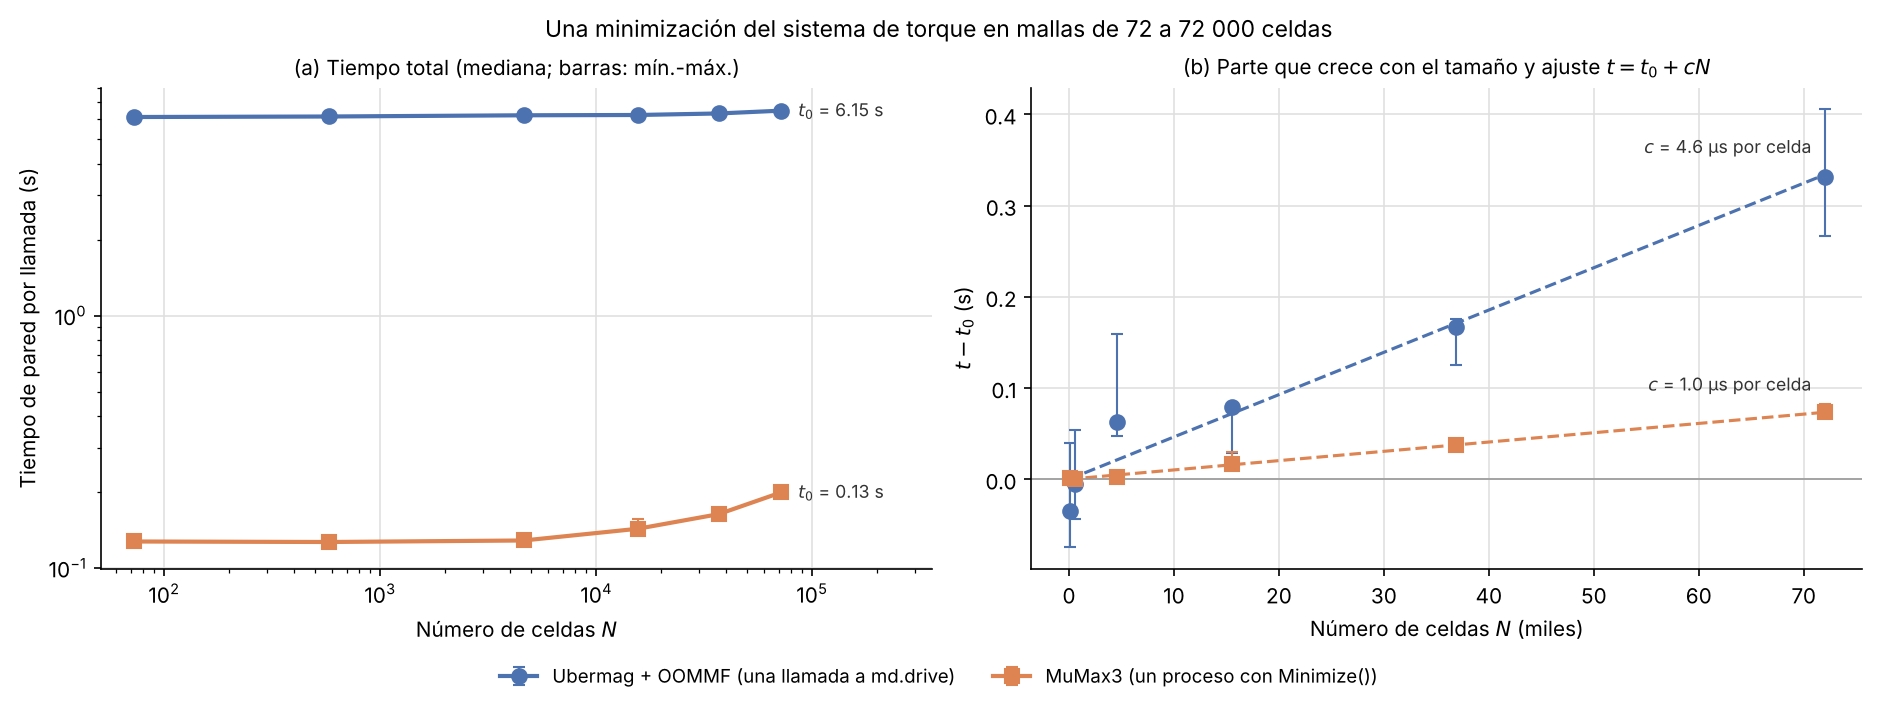

**Este cociente no es una medida de la velocidad de los métodos**, por tres razones:

1. **El costo por llamada de OOMMF casi no depende del tamaño del problema.** De los 6.47 s de cada llamada del barrido, 6.15 s son el costo fijo de lanzar OOMMF; el cociente de 316.0 mide sobre todo cuántas veces se paga ese costo.
2. **Los criterios de parada son distintos** (sección 8.5): `MinDriver` de OOMMF usa gradiente conjugado, doble precisión y un criterio sobre el par residual; `Minimize()` de MuMax3 usa descenso de gradiente, precisión simple y un criterio sobre el cambio de $\mathbf m$ entre iteraciones.
3. **Se comparan una CPU y una GPU**, y un notebook completo (con gráficas) con un script.

Por tanto, el cociente mide el flujo de trabajo (una llamada a OOMMF por cada ángulo frente a un único proceso en GPU) y no la velocidad de los métodos.

### 8.5 Conclusiones de la comparación

1. **Los dos programas dan la misma curva de torque.** Con los datos numéricos de los dos códigos, las curvas coinciden en los 71 ángulos con una diferencia máxima de $3.9\times10^{-5}$ de la amplitud, con periodo $\pi$, simetría impar y amplitud de $0.95\times10^{6}$ N m$^{-2}$.
2. **El torque por unidad de volumen es la magnitud comparable**: $\mu_0\langle\mathbf M\rangle\times\mathbf H$ en `mag2exp` y $M_s\langle\mathbf m\rangle\times\mathbf B_\mathrm{ext}$ en MuMax3 son la misma cantidad.
3. **La amplitud es $K_\mathrm{eff}$, no $K$.** El modelo de macroespín con los factores desmagnetizantes de la caja reproduce la simulación con una diferencia máxima de 1.2 %, y atribuye a la forma la reducción de la amplitud.
4. **Al comparar promedios hay que fijar la región.** El promedio de $m_z$ sobre toda la caja (0.9978) y el del plano central (>0.99998) difieren por la inclinación cerca de las caras.
5. **El cociente de tiempos (316.0) mide sobre todo el costo fijo de OOMMF.** Cada una de las 72 llamadas paga unos 6.15 s de arranque, independientes del tamaño del problema, y el cálculo con 72 000 celdas añade unos 0.33 s; MuMax3 hace todo el barrido en un único proceso en GPU de 1.5 s (sección 8.4).

**Niveles de equivalencia entre las dos implementaciones**

| Nivel | ¿Equivalentes? | Observación |
|---|---|---|
| Física | Sí | Mismos $M_s$, $A$, $K$, geometría de $300\times300\times100$ nm$^3$, campo desmagnetizante completo y campo de $2.38\times10^{6}$ A/m rotando en el plano $yz$. |
| Discretización | Sí | Misma malla de $60\times60\times20$ celdas de 5 nm. |
| Numérica | Parcial | Distinto algoritmo, precisión y criterio de parada: OOMMF (gradiente conjugado, doble precisión) se detiene con $\lvert\mathbf m\times\mathbf H\rvert<0.1$ A/m (valor por defecto de `oommfc` 0.66.0); MuMax3 (descenso de gradiente, precisión simple), con un cambio máximo de $\mathbf m$ menor que $10^{-6}$. En ambos, cada minimización parte del estado anterior. |
| Observables | Sí | Mismo torque por unidad de volumen, $\mu_0\langle\mathbf M\rangle\times\mathbf H$; la curva coincide con la de Ubermag a $3.9\times10^{-5}$ de la amplitud. |

## Referencias

**Fuentes académicas**

Aharoni, A. (1998). Demagnetizing factors for rectangular ferromagnetic prisms. *Journal of Applied Physics, 83*(6), 3432-3434. https://doi.org/10.1063/1.367113

Aharoni, A. (2000). *Introduction to the theory of ferromagnetism* (2.ª ed.). Oxford University Press.

Beg, M., Lang, M., & Fangohr, H. (2022). Ubermag: Toward more effective micromagnetic workflows. *IEEE Transactions on Magnetics, 58*(2), 1-5. https://doi.org/10.1109/TMAG.2021.3078896

Blundell, S. (2001). *Magnetism in condensed matter*. Oxford University Press.

Brown, W. F. (1963). *Micromagnetics*. Interscience Publishers.

Donahue, M. J., & Porter, D. G. (1999). *OOMMF user's guide, version 1.0* (NISTIR 6376). National Institute of Standards and Technology. https://doi.org/10.6028/NIST.IR.6376

Dunsmore, M. G., Thibault, J. A., Fast, K. R., Sauer, V. T. K., Losby, J. E., Diao, Z., Belov, M., & Freeman, M. R. (2022). Three-axis torque investigation of interfacial exchange coupling in a NiFe/CoO bilayer micromagnetic disk. *AIP Advances, 12*(3). https://doi.org/10.1063/9.0000345

Exl, L., Bance, S., Reichel, F., Schrefl, T., Peter Stimming, H., & Mauser, N. J. (2014). LaBonte's method revisited: An effective steepest descent method for micromagnetic energy minimization. *Journal of Applied Physics, 115*(17), 17D118. https://doi.org/10.1063/1.4862839

Holt, S. J. R., Lang, M., Loudon, J. C., Hicken, T. J., Suess, D., Cortés-Ortuño, D., Pathak, S. A., Beg, M., Zulfiqar, K., & Fangohr, H. (2025). Virtual experiments in computational magnetism with mag2exp. *npj Computational Materials, 11*, 201. https://doi.org/10.1038/s41524-025-01686-3

Jackson, J. D. (1999). *Classical electrodynamics* (3.ª ed.). Wiley.

Stoner, E. C., & Wohlfarth, E. P. (1948). A mechanism of magnetic hysteresis in heterogeneous alloys. *Philosophical Transactions of the Royal Society of London. Series A, 240*(826), 599-642.

Vansteenkiste, A., Leliaert, J., Dvornik, M., Helsen, M., Garcia-Sanchez, F., & Van Waeyenberge, B. (2014). The design and verification of MuMax3. *AIP Advances, 4*(10), 107133. https://doi.org/10.1063/1.4899186

**Fuentes complementarias**

Ubermag developers. (s. f.). *Torque magnetometry*. Ubermag documentation. https://ubermag.github.io/documentation/notebooks/mag2exp/Torque_magnetometry.html

MuMax3 developers. (s. f.). *mumax3 API*. https://mumax.github.io/api.html

MuMax3 developers. (s. f.). *mumax/3* [Código fuente]. GitHub. https://github.com/mumax/3

OOMMF Documentation Team. (2023). *OOMMF programming manual: OOMMF variable types and macros*. National Institute of Standards and Technology. https://math.nist.gov/oommf/doc/progman21a0/progman/OOMMF_Variable_Types_Macros.html

Ubermag developers. (s. f.). *oommfc* (versión 0.66.0) [Código fuente]. GitHub. https://github.com/ubermag/oommfc